In [15]:
import dsi #De Simone Inference module
import numpy as np
import matplotlib.pyplot as plt
from dsi import xp

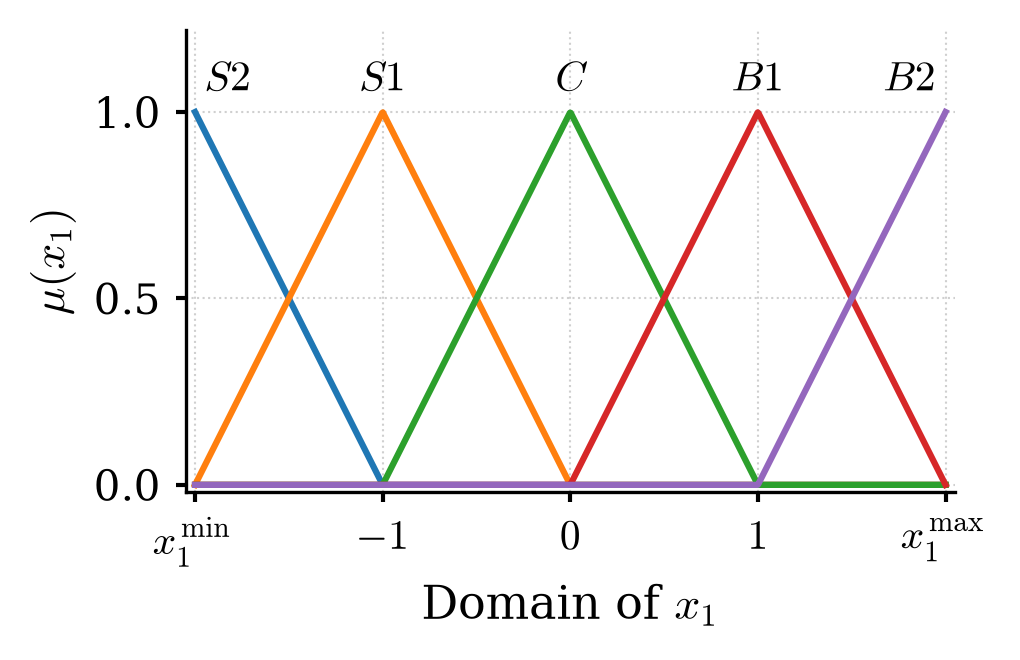

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Configurazione stile tipografico standard da paper
plt.rcParams.update(
    {
        "font.family": "serif",
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

x_min = -2
x_max = 2
P = 5
N = 1000
labels = [r"$S2$", r"$S1$", r"$C$", r"$B1$", r"$B2$"]

x = np.linspace(x_min, x_max, N)
pivots = np.pad(np.linspace(x_min, x_max, P), (1, 1), mode="edge")
arr_GPU = xp.asarray(x)

# Dimensione standard a colonna singola (3.5 pollici di larghezza, rapporto aureo/4:3)
fig, ax = plt.subplots(figsize=(3.5, 2.3), dpi=300)

# Palette sobria o toni coordinati (puoi usare anche un solo colore o stili di linea)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

for i in range(P):
    fuzzy_set = dsi.triang_fs(arr_GPU, pivots[i], pivots[i + 1], pivots[i + 2])
    y_vals = fuzzy_set.get()
    
    ax.plot(x, y_vals, color=colors[i], linewidth=1.5)
    
    # Etichetta del set fuzzy posizionata sopra il picco
    # Allineamento differenziato per evitare sovrapposizioni con gli assi
    if i == 0:
      ha = "left"
      offset = 0.05  # sposta leggermente verso l'interno
    elif i == P - 1:
      ha = "right"
      offset = -0.05
    else:
      ha = "center"
      offset = 0.0
    
    ax.text(
        pivots[i + 1] + offset,
        1.03,
        labels[i],
        ha=ha,
        va="bottom",
        fontsize=10,
        fontweight="semibold",
    )

# Ticks puliti: x_min e x_max con i valori numerici intermedi
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_xticklabels([r"$x_1^{\min}$", "$-1$", "$0$", "$1$", r"$x_1^{\max}$"])

ax.set_yticks([0.0, 0.5, 1.0])
ax.set_ylim(-0.02, 1.22)
ax.set_xlim(-2.05, 2.05)

# Label formali
ax.set_xlabel(r"Domain of $x_1$")
ax.set_ylabel(r"$\mu(x_1)$")

# Griglia leggera e pulita
ax.grid(True, linestyle=":", alpha=0.6)

# Despine: rimuove i bordi superfluo in alto e a destra tipici dei paper moderni
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Per includerlo nel paper preservando la qualità vettoriale:
plt.savefig("fuzzy_partition.png", bbox_inches='tight')

plt.show()